# HCT116 Analysis

MIA-Jet top-called vs. random-called jets in HCT116 (RAD21-auxin 0hr/6hr, Hi-C and intact Hi-C) compared against repli-seq data:

1. ECDF of distance to the closest 6hr repli-seq IZ zone (`early`)
2. ECDF of distance to the closest 0hr repli-seq IZ zone (`early`)
3. IZ overlap composition with the 0hr repli-seq IZ zones (0hr Hi-C)
4. Median 0hr repli-seq signal across the 16 S-phase fractions (P02-P17) with 25th/75th percentile bands

In [1]:
import sys
sys.path.append('..')
from utils.plotting import genomic_labels
from notebooks.func_analysis import extract_chipseq_values

import os
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bioframe as bf
from pybedtools import BedTool
from statsmodels.distributions.empirical_distribution import ECDF
from scipy.stats import ks_2samp

In [2]:
cf = """
samples:


  HCT116_RAD21-auxin-0hr_hic_Rao-2017_4DNFIP71EWXC_hg38_10kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/HCT116_RAD21-auxin-0hr_hic_Rao-2017_4DNFIP71EWXC_hg38.hic"
    genome: "hg38"
    norm: "VC_SQRT"
    res: "10000" 
    exp: "hic"
    mcool: "/nfs/turbo/umms-minjilab/downloaded_data/HCT116_RAD21-auxin-0hr_hic_Rao-2017_4DNFIP71EWXC_hg38.ice.mcool"
    win: "1200000"
    chroms: "all"
    # compartment: "False"
    # chroms: "chr2"
    root_within: "5"
    length: "8"
    q_val: "0.5"
    extra_args:
    - "--diagnostic_plots"

  HCT116_RAD21-auxin-6hr_hic_Rao-2017_4DNFILIM6FDL_hg38_10kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/HCT116_RAD21-auxin-6hr_hic_Rao-2017_4DNFILIM6FDL_hg38.hic"
    genome: "hg38"
    norm: "VC_SQRT"
    res: "10000" 
    exp: "hic"
    mcool: "/nfs/turbo/umms-minjilab/downloaded_data/HCT116_RAD21-auxin-6hr_hic_Rao-2017_4DNFILIM6FDL_hg38.ice.mcool"
    win: "1200000"
    chroms: "all"
    compartment: "False"
    root_within: "5"
    length: "8"
    q_val: "0.5"
    extra_args:
    - "--diagnostic_plots"

  HCT116_RAD21-auxin-0hr_intacthic_Guckelberger-2024_ENCFF528XGK_hg38_10kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/HCT116_RAD21-auxin-0hr_intacthic_Guckelberger-2024_ENCFF528XGK_hg38.hic"
    genome: "hg38"
    norm: "VC_SQRT" # KR failed
    res: "10000" 
    exp: "hic"
    mcool: "/nfs/turbo/umms-minjilab/downloaded_data/HCT116_RAD21-auxin-0hr_intacthic_Guckelberger-2024_ENCFF109GNA_hg38.ice.mcool"
    win: "1200000"
    chroms: "all"
    # compartment: "False"
    root_within: "5"
    length: "8"
    q_val: "0.5"

  HCT116_RAD21-auxin-6hr_intacthic_Guckelberger-2024_ENCFF317OIA_hg38_10kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/HCT116_RAD21-auxin-6hr_intacthic_Guckelberger-2024_ENCFF317OIA_hg38.hic"
    genome: "hg38"
    norm: "VC_SQRT" # KR failed
    res: "10000" 
    exp: "hic"
    mcool: "/nfs/turbo/umms-minjilab/downloaded_data/HCT116_RAD21-auxin-6hr_intacthic_Guckelberger-2024_ENCFF461RFV_hg38.ice.mcool"
    win: "1200000"
    chroms: "all"
    compartment: "False"
    root_within: "5"
    length: "8"
    q_val: "0.5"

"""


genome = "hg38"

config = yaml.safe_load(cf)

samples = config["samples"]

In [3]:
def read_bed(bed):
    with open(bed) as f:
        first_line = f.readline().rstrip("\n")

    if first_line.startswith("#"):
        header = first_line.lstrip("#").split("\t")
        bed = pd.read_csv(bed, sep="\t", names=header, comment="#")
        bed = bed.rename({"genomic_coords" : "unique_id", "unique_id" : "unique_id_miajet"}, axis=1)
    else:
        bed = pd.read_csv(bed, sep="\t", header=None, comment="#")
        bed = bed.rename({0 : "chrom", 1 : "start", 2 : "end", 4 : "unique_id"}, axis=1)

    if len(bed.columns) <= 3:
        # Then we need to make a fake unique_id column
        bed["unique_id"] = np.arange(len(bed))

    return bed

In [4]:
# Analysis parameters
output_name = "v2.0.3"
results_dir = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/"
save_path = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/analysis_{output_name}"

os.makedirs(save_path, exist_ok=True)

data_name = "HCT116 cell-line"

plusminus = int(10e3)

# MIA-Jet results
bed_type = "midpoint" # midpoint | jet-length

names = []
bed_top_called_list = []
bed_random_called_list = []

for key, attributes in samples.items():
    print(f"Processing experiment: {key}")
    names.append(key)

    resolution = genomic_labels(int(attributes["res"]))

    hic_name = os.path.basename(attributes["file"]).split('.hic')[0]

    if "0hr" in key:
        # 0hr has compartments
        rt = "q_val_0.5-0.95"
    else:
        # 6hr has no compartments
        rt = "q_val_0.5"

    print(f"Using result type: {rt} for experiment: {key}")
    fs = os.path.join(results_dir, f"{hic_name}_chr_combined_{resolution}", f"{hic_name}_chr_combined_{rt}_{resolution}_summary_table.csv")

    # Get file names
    if bed_type == "jet-length":
        replacement_str = "jet-length.bed"
    else:
        replacement_str = f"jet-mp-{plusminus}.bed"

    f_bed_top_called = fs.replace("_summary_table.csv", f"_top-called_{replacement_str}")
    f_bed_random_called = fs.replace("_summary_table.csv", f"_random-called_{replacement_str}")

    bed_top_called = read_bed(f_bed_top_called)
    print(len(bed_top_called))

    bed_random_called = read_bed(f_bed_random_called)

    bed_top_called_list.append(bed_top_called)
    bed_random_called_list.append(bed_random_called)

Processing experiment: HCT116_RAD21-auxin-0hr_hic_Rao-2017_4DNFIP71EWXC_hg38_10kb
Using result type: q_val_0.5-0.95 for experiment: HCT116_RAD21-auxin-0hr_hic_Rao-2017_4DNFIP71EWXC_hg38_10kb
274
Processing experiment: HCT116_RAD21-auxin-6hr_hic_Rao-2017_4DNFILIM6FDL_hg38_10kb
Using result type: q_val_0.5 for experiment: HCT116_RAD21-auxin-6hr_hic_Rao-2017_4DNFILIM6FDL_hg38_10kb
137
Processing experiment: HCT116_RAD21-auxin-0hr_intacthic_Guckelberger-2024_ENCFF528XGK_hg38_10kb
Using result type: q_val_0.5-0.95 for experiment: HCT116_RAD21-auxin-0hr_intacthic_Guckelberger-2024_ENCFF528XGK_hg38_10kb
162
Processing experiment: HCT116_RAD21-auxin-6hr_intacthic_Guckelberger-2024_ENCFF317OIA_hg38_10kb
Using result type: q_val_0.5 for experiment: HCT116_RAD21-auxin-6hr_intacthic_Guckelberger-2024_ENCFF317OIA_hg38_10kb
101


In [5]:
names_abrev = [
    "0hr Hi-C", "6hr Hi-C", "0hr Intact Hi-C", "6hr Intact Hi-C"
]

## ECDF to closest IZ zone

In [6]:
def df_to_bedtool(df, cols=("chrom", "start", "end")):
    """
    Convert a dataframe with chrom/start/end columns into a sorted BED3 BedTool.
    Keeps only BED3 columns so the closest distance is always the last field.
    """
    bed_df = df.loc[:, list(cols)].copy()
    bed_df["start"] = bed_df["start"].astype(int)
    bed_df["end"] = bed_df["end"].astype(int)

    bed_df = bed_df.dropna()
    bed_df = bed_df.loc[bed_df["end"] > bed_df["start"]]

    bed_df = bed_df.sort_values(["chrom", "start", "end"], kind="mergesort")
    return BedTool.from_dataframe(bed_df).sort()


def make_iz_bedtool(df_iz_subset):
    """
    Build a merged IZ BedTool using bedtools merge instead of custom merge_intervals().
    """
    if df_iz_subset.empty:
        return None

    iz_bt = df_to_bedtool(df_iz_subset, cols=("chrom", "start", "end"))
    return iz_bt.merge()


def distances_to_iz_closest(df, iz_bt):
    """
    Distance from each interval in df to the closest merged IZ interval.

    Equivalent behavior to your manual search:
      - overlapping IZ => distance 0
      - otherwise nearest genomic gap
      - intervals on chromosomes with no IZ are ignored
    """
    if df.empty or iz_bt is None:
        return np.array([], dtype=float)

    a_bt = df_to_bedtool(df, cols=("chrom", "start", "end"))

    closest_bt = a_bt.closest(
        iz_bt,
        d=True,       # append distance as last column
        t="first",    # avoid duplicate rows for ties
    )

    dists = []
    for rec in closest_bt:
        # With BED3 A and BED3 B, distance is the final field.
        # If no B feature exists on the same chromosome, bedtools reports -1 fields.
        try:
            dist = int(rec.fields[-1])
        except ValueError:
            continue

        if dist >= 0:
            dists.append(dist)

    return np.asarray(dists, dtype=float)


def ecdf_xy(values):
    """
    ECDF using statsmodels instead of a custom ECDF implementation.
    """
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return np.array([]), np.array([])

    f = ECDF(values)
    finite = np.isfinite(f.x)

    return f.x[finite], f.y[finite]

### 6hr repliseq IZ

In [7]:
f_repliseq_iz_zone = "/nfs/turbo/umms-minjilab/downloaded_data/HCT116_6h_repliseq_IZ_4DNFIGOMS9G7_peak.txt"

name = os.path.basename(f_repliseq_iz_zone).split('.')[0]
df_iz = pd.read_csv(f_repliseq_iz_zone, sep='\t', header=None, names=["chrom", "start", "end", "name"])

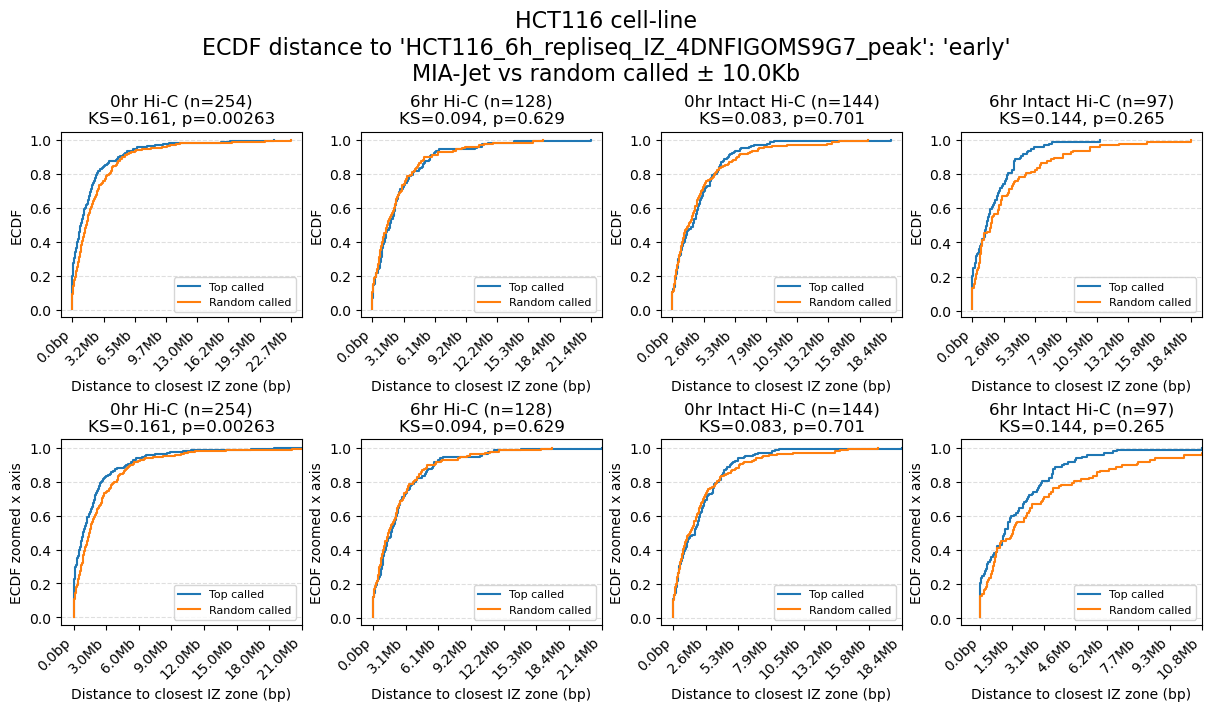

In [8]:
iz_subset = "early"

df_iz_subset = df_iz.loc[df_iz['name'] == iz_subset].reset_index(drop=True)
iz_bt = make_iz_bedtool(df_iz_subset)

n_plots = len(bed_top_called_list)
fig, axes = plt.subplots(2, n_plots, figsize=(3 * n_plots, 7), layout="constrained")

axes = np.array(axes).reshape(2, n_plots)

num_ticks = 8

for i in range(n_plots):
    ax = axes[0, i]
    ax_zoom = axes[1, i]

    top_dist = distances_to_iz_closest(bed_top_called_list[i], iz_bt)
    rnd_dist = distances_to_iz_closest(bed_random_called_list[i], iz_bt)

    x_top, y_top = ecdf_xy(top_dist)
    x_rnd, y_rnd = ecdf_xy(rnd_dist)

    ks_stat, ks_pval = ks_2samp(top_dist, rnd_dist)

    for j, a in enumerate([ax, ax_zoom]):
        a.step(x_top, y_top, where="post", label="Top called")
        a.step(x_rnd, y_rnd, where="post", label="Random called")

        title = f"{names_abrev[i]} (n={len(top_dist)})\nKS={ks_stat:.3f}, p={ks_pval:.3g}"
        a.set_title(title)
        a.set_xlabel("Distance to closest IZ zone (bp)")

        if j == 1:
            a.set_ylabel("ECDF zoomed x axis")
        else:
            a.set_ylabel("ECDF")

        a.grid(axis="y", linestyle="--", alpha=0.4)
        a.legend(fontsize=8)

    ax_zoom.set_xlim(None, x_top[-1])

    xticks = np.linspace(min(x_top[0], x_rnd[0]), max(x_top[-1], x_rnd[-1]), num_ticks)
    ax.set_xticks(xticks)
    ax.set_xticklabels(
        [genomic_labels(x, N=1) for x in xticks],
        fontsize=10,
        rotation=45,
        ha="right",
    )

    xticks = np.linspace(min(x_top[0], x_rnd[0]), x_top[-1], num_ticks)
    ax_zoom.set_xticks(xticks)
    ax_zoom.set_xticklabels(
        [genomic_labels(x, N=1) for x in xticks],
        fontsize=10,
        rotation=45,
        ha="right",
    )

fig.suptitle(f"{data_name}\nECDF distance to '{name}': '{iz_subset}'\nMIA-Jet vs random called ± {genomic_labels(plusminus, N=1)}", fontsize=16)

save_fname = (
    f"{save_path}/{data_name}_{name}_{iz_subset}_"
    f"Top-called_vs_Random-called_"
    f"ECDF_{plusminus}.png"
)

plt.savefig(save_fname, dpi=500)

plt.show()

### 0hr repliseq IZ

In [9]:
f_repliseq_iz_zone = "/nfs/turbo/umms-minjilab/downloaded_data/HCT116_0h_repliseq_IZ_4DNFIYO3H24N_peak.txt"

name = os.path.basename(f_repliseq_iz_zone).split('.')[0]
df_iz = pd.read_csv(f_repliseq_iz_zone, sep='\t', header=None, names=["chrom", "start", "end", "name"])

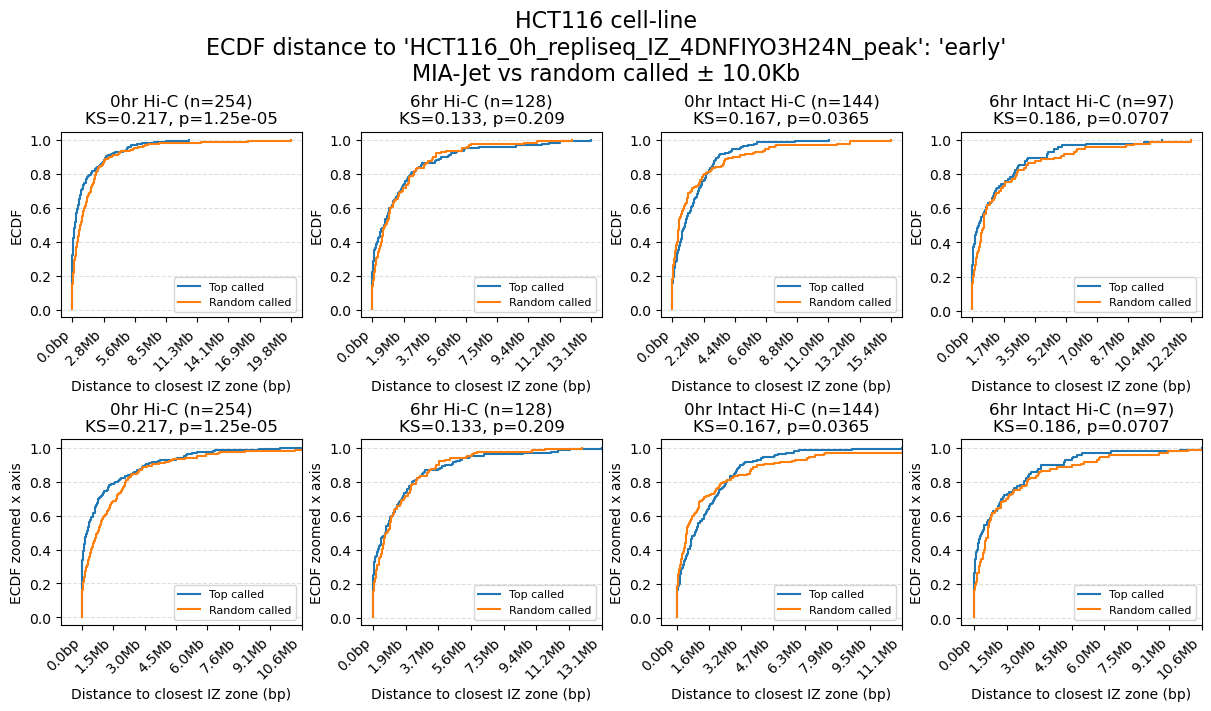

In [10]:
iz_subset = "early"

df_iz_subset = df_iz.loc[df_iz['name'] == iz_subset].reset_index(drop=True)
iz_bt = make_iz_bedtool(df_iz_subset)

n_plots = len(bed_top_called_list)
fig, axes = plt.subplots(2, n_plots, figsize=(3 * n_plots, 7), layout="constrained")

axes = np.array(axes).reshape(2, n_plots)

num_ticks = 8

for i in range(n_plots):
    ax = axes[0, i]
    ax_zoom = axes[1, i]

    top_dist = distances_to_iz_closest(bed_top_called_list[i], iz_bt)
    rnd_dist = distances_to_iz_closest(bed_random_called_list[i], iz_bt)

    x_top, y_top = ecdf_xy(top_dist)
    x_rnd, y_rnd = ecdf_xy(rnd_dist)

    ks_stat, ks_pval = ks_2samp(top_dist, rnd_dist)

    for j, a in enumerate([ax, ax_zoom]):
        a.step(x_top, y_top, where="post", label="Top called")
        a.step(x_rnd, y_rnd, where="post", label="Random called")

        title = f"{names_abrev[i]} (n={len(top_dist)})\nKS={ks_stat:.3f}, p={ks_pval:.3g}"
        a.set_title(title)
        a.set_xlabel("Distance to closest IZ zone (bp)")

        if j == 1:
            a.set_ylabel("ECDF zoomed x axis")
        else:
            a.set_ylabel("ECDF")

        a.grid(axis="y", linestyle="--", alpha=0.4)
        a.legend(fontsize=8)

    ax_zoom.set_xlim(None, x_top[-1])

    xticks = np.linspace(min(x_top[0], x_rnd[0]), max(x_top[-1], x_rnd[-1]), num_ticks)
    ax.set_xticks(xticks)
    ax.set_xticklabels(
        [genomic_labels(x, N=1) for x in xticks],
        fontsize=10,
        rotation=45,
        ha="right",
    )

    xticks = np.linspace(min(x_top[0], x_rnd[0]), x_top[-1], num_ticks)
    ax_zoom.set_xticks(xticks)
    ax_zoom.set_xticklabels(
        [genomic_labels(x, N=1) for x in xticks],
        fontsize=10,
        rotation=45,
        ha="right",
    )

fig.suptitle(f"{data_name}\nECDF distance to '{name}': '{iz_subset}'\nMIA-Jet vs random called ± {genomic_labels(plusminus, N=1)}", fontsize=16)

save_fname = (
    f"{save_path}/{data_name}_{name}_{iz_subset}_"
    f"Top-called_vs_Random-called_"
    f"ECDF_{plusminus}.png"
)

plt.savefig(save_fname, dpi=500)

plt.show()

## Fraction bar chart IZ intersection

In [11]:
def df_to_named_bedtool(df, cols=("chrom", "start", "end", "name")):
    """chrom/start/end/name -> sorted BedTool (name kept for categorisation)."""
    bed_df = df.loc[:, list(cols)].copy()
    bed_df["start"] = bed_df["start"].astype(int)
    bed_df["end"] = bed_df["end"].astype(int)
    bed_df = bed_df.dropna(subset=["chrom", "start", "end"])
    bed_df = bed_df.loc[bed_df["end"] > bed_df["start"]]
    bed_df = bed_df.sort_values(["chrom", "start", "end"], kind="mergesort")
    return BedTool.from_dataframe(bed_df).sort()


def categorize_by_iz(df, iz_named_bt, priority):
    """
    Assign each feature in df to exactly one bucket:
      - "none" if it overlaps no IZ
      - else the highest-priority IZ 'name' it overlaps
        (priority = position in `priority`, earlier = higher)
    Returns a pd.Series of labels (one per BED3-valid feature).
    """
    if df.empty or iz_named_bt is None:
        return pd.Series([], dtype=object)

    a_df = df.loc[:, ["chrom", "start", "end"]].copy()
    a_df["start"] = a_df["start"].astype(int)
    a_df["end"] = a_df["end"].astype(int)
    a_df = a_df.dropna()
    a_df = a_df.loc[a_df["end"] > a_df["start"]].reset_index(drop=True)
    a_df["row_id"] = np.arange(len(a_df))

    a_bt = BedTool.from_dataframe(a_df[["chrom", "start", "end", "row_id"]]).sort()

    # left outer join: every A row kept; B 'name' == "." when no overlap
    rank = {nm: r for r, nm in enumerate(priority)}
    best = {}  # row_id -> (rank, name)
    for rec in a_bt.intersect(iz_named_bt, loj=True):
        f = rec.fields
        row_id = int(f[3])
        iz_name = f[-1]              # last field = B 'name'
        if iz_name == "." or iz_name not in rank:
            continue
        if row_id not in best or rank[iz_name] < best[row_id][0]:
            best[row_id] = (rank[iz_name], iz_name)

    labels = [best.get(rid, (None, "none"))[1] for rid in a_df["row_id"]]
    return pd.Series(labels, dtype=object)


def composition_counts(labels, categories):
    counts = pd.Series(labels).value_counts() if len(labels) else pd.Series(dtype=int)
    return {c: int(counts.get(c, 0)) for c in categories}

### 0hr repliseq IZ

In [12]:
# Uses the 0hr repli-seq IZ zones (df_iz, name) loaded in the ECDF section above
iz_slop = int(10e3) # set to 0 to disable (plusminus)

# genome dict for bedtools slop (clamps at chrom ends / 0)
cs = bf.fetch_chromsizes(genome)
chromsizes_dict = {c: (0, int(s)) for c, s in cs.items()}

iz_named_bt = df_to_named_bedtool(df_iz)
if iz_slop > 0:
    iz_named_bt = iz_named_bt.slop(b=iz_slop, genome=chromsizes_dict).sort()

iz_names = list(df_iz["name"].unique())
all_categories = ["none"] + iz_names          # stacking order: "none" first

observed_counts, random_counts = [], []
observed_n, random_n = [], []
for i in range(len(bed_top_called_list)):
    obs_lab = categorize_by_iz(bed_top_called_list[i],    iz_named_bt, iz_names)
    rnd_lab = categorize_by_iz(bed_random_called_list[i], iz_named_bt, iz_names)

    observed_counts.append(composition_counts(obs_lab, all_categories))
    random_counts.append(composition_counts(rnd_lab, all_categories))
    observed_n.append(len(obs_lab))
    random_n.append(len(rnd_lab))

    print(f"{names_abrev[i]:>18s} | observed n={len(obs_lab):5d} | random n={len(rnd_lab):5d}")

          0hr Hi-C | observed n=  274 | random n=  274
          6hr Hi-C | observed n=  137 | random n=  137
   0hr Intact Hi-C | observed n=  162 | random n=  162
   6hr Intact Hi-C | observed n=  101 | random n=  101


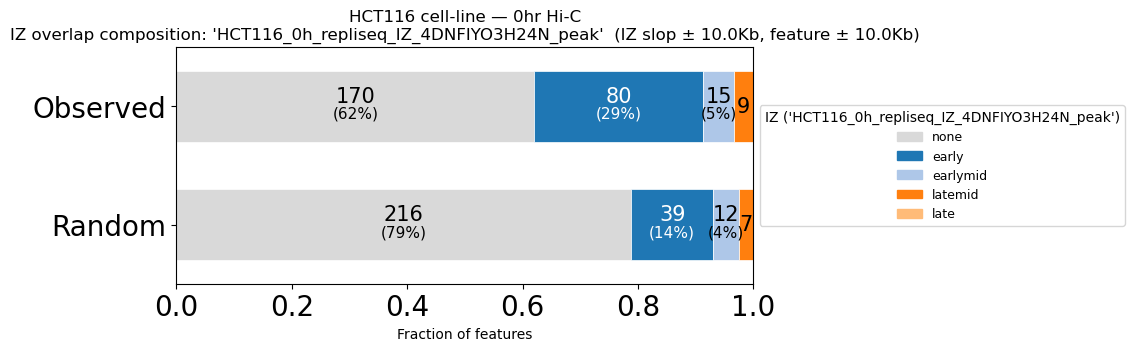

In [13]:
def _text_color(rgba):
    r, g, b = rgba[:3]
    return "white" if (0.299 * r + 0.587 * g + 0.114 * b) < 0.5 else "black"


cmap = plt.get_cmap("tab20")
colors = {c: cmap(k % 20) for k, c in enumerate(iz_names)}
colors["none"] = (0.85, 0.85, 0.85, 1.0)

i = 0  # first experiment only (0hr Hi-C)

fig, ax = plt.subplots(figsize=(11, 3.4), layout="constrained")

rows = [
    ("Observed", observed_counts[i], observed_n[i], 1),   # top
    ("Random",   random_counts[i],   random_n[i],   0),   # bottom
]

for _, counts, n, y in rows:
    left = 0.0
    for cat in all_categories:
        cnt = counts.get(cat, 0)
        frac = cnt / n if n else 0.0
        if frac <= 0:
            continue
        col = colors[cat]
        ax.barh(y, frac, left=left, height=0.6, color=col,
                edgecolor="white", linewidth=0.5)

        x = left + frac / 2
        tcol = _text_color(col)
        if frac >= 0.04:
            ax.text(x, y, f"{cnt}", ha="center", va="bottom",
                    fontsize=15, color=tcol)
            ax.text(x, y, f"({frac * 100:.0f}%)", ha="center", va="top",
                    fontsize=11, color=tcol)
        else:
            # not much space so don't plot the fraction
            ax.text(x, y, f"{cnt}", ha="center", va="center",
                    fontsize=15, color=tcol)
        left += frac

ax.set_yticks([0, 1])
ax.set_yticklabels(["Random", "Observed"])
ax.set_ylim(-0.5, 1.5)
ax.set_xlim(0, 1)
ax.set_xlabel("Fraction of features")

ax.tick_params(axis='both', labelsize=20)

handles = [plt.Rectangle((0, 0), 1, 1, color=colors[c]) for c in all_categories]
ax.legend(handles, all_categories, loc="center left",
          bbox_to_anchor=(1.0, 0.5), fontsize=9, title=f"IZ ('{name}')")

ax.set_title(
    f"{data_name} — {names_abrev[i]}\n"
    f"IZ overlap composition: '{name}'  "
    f"(IZ slop ± {genomic_labels(iz_slop, N=1)}, feature ± {genomic_labels(plusminus, N=1)})",
    fontsize=12,
)

save_fname = (
    f"{save_path}/{data_name}_{names[i]}_{name}_"
    f"IZ-composition_slop-{iz_slop}_pm-{plusminus}.png"
)

plt.savefig(save_fname, dpi=300, bbox_inches="tight")

plt.show()

## Medians across 16 stages

In [14]:
chromsizes = bf.fetch_chromsizes(genome, as_bed=True)
common_chroms = list(chromsizes["chrom"].values)
common_chroms.remove('chrY')
common_chroms.remove('chrM')
common_chroms.remove('chrX') # Needed for Repliseq data read in (chrX is not in the bigWigs)
# This reduces the number of jets from 274 to 254

In [15]:
# READ IN REPLI-SEQ (0h)
f_chrom_sizes = "/nfs/turbo/umms-minjilab/processing/genomes/hg38/hg38.chrom.sizes"

repliseq_dir = "/nfs/turbo/umms-minjilab/downloaded_data"
chip_files = [
    f"{repliseq_dir}/HCT116_0h_repliseq-P{idx:02d}.bigWig"
    for idx in range(2, 18)
]

chip_names_abrev = [f"P{idx:02d}" for idx in range(2, 18)]

In [16]:
observed_type = "Top called"
background_type = "Random called"

observed_table = bed_top_called_list
background_table = bed_random_called_list

stat = "max"
chipseq_resolution = 10000  # 10 kb

obs_intervals = [df.reset_index(drop=True) for df in observed_table]
bg_intervals = [df.reset_index(drop=True) for df in background_table]

# One file read for all observed intervals
chipseq_obs_dicts = extract_chipseq_values(
    chip_files,
    obs_intervals,
    f_chrom_sizes,
    common_chroms,
    names,
    stat=stat,
)

# One file read for all background intervals
chipseq_bg_dicts = extract_chipseq_values(
    chip_files,
    bg_intervals,
    f_chrom_sizes,
    common_chroms,
    names,
    stat=stat,
)

# Convert dicts to arrays (per file -> per experiment)
chipseq_obs = [
    [np.asarray(list(d.values())) for d in file_dicts]
    for file_dicts in chipseq_obs_dicts
]
chipseq_bg = [
    [np.asarray(list(d.values())) for d in file_dicts]
    for file_dicts in chipseq_bg_dicts
]

# Pack for plotting cell
collected_chipseq = {
    "observed_type": observed_type,
    "background_type": background_type,
    "stat": stat,
    "chipseq_resolution": chipseq_resolution,
    "obs_values": chipseq_obs,
    "bg_values": chipseq_bg,
}

chr1 is already loaded


chr2 is already loaded


chr3 is already loaded


chr4 is already loaded


chr5 is already loaded


chr6 is already loaded


... (2,038 outputs left out)

chr20 is already loaded


chr21 is already loaded


chr22 is already loaded


No jets called for chromosome chr5 by HCT116_RAD21-auxin-0hr_intacthic_Guckelberger-2024_ENCFF528XGK_hg38_10kb
No jets called for chromosome chr22 by HCT116_RAD21-auxin-0hr_intacthic_Guckelberger-2024_ENCFF528XGK_hg38_10kb
No jets called for chromosome chr2 by HCT116_RAD21-auxin-6hr_intacthic_Guckelberger-2024_ENCFF317OIA_hg38_10kb


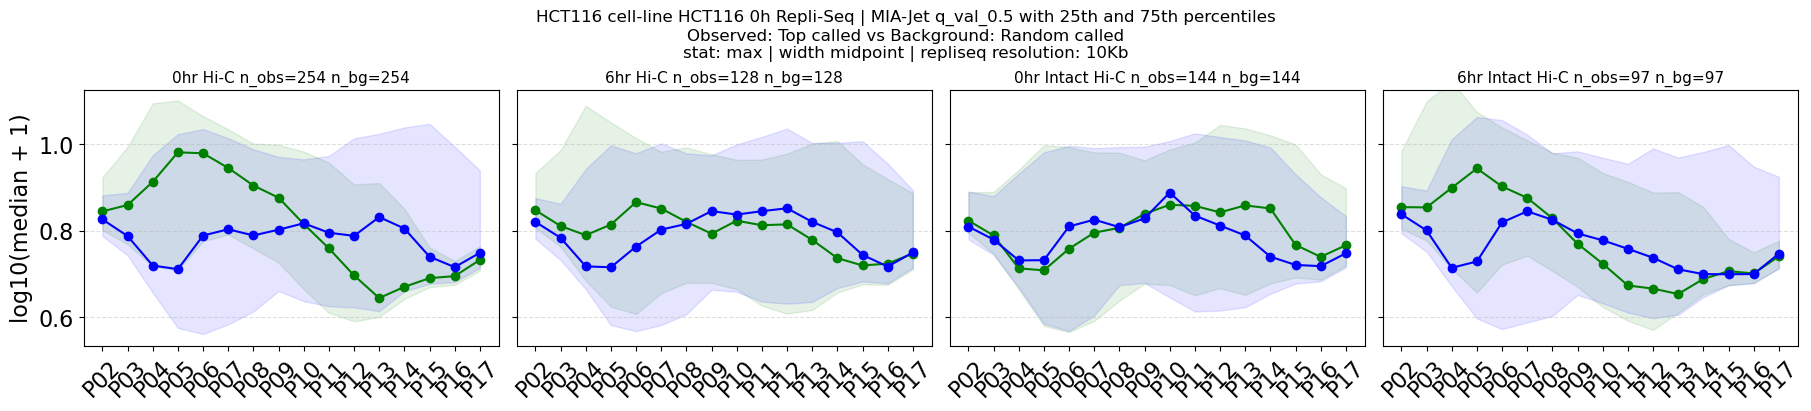

In [17]:
# PLOTTING
obs_type = collected_chipseq["observed_type"]
bg_type = collected_chipseq["background_type"]
stat = collected_chipseq["stat"]
chipseq_resolution = collected_chipseq["chipseq_resolution"]

obs_values = collected_chipseq["obs_values"]
bg_values = collected_chipseq["bg_values"]

obs_col, bg_col = "green", "blue"
alpha = 0.1  # band opacity

num_files = len(chip_files)
num_exp = len(names)
fig, axes = plt.subplots(
    1,
    num_exp,
    figsize=(4.5 * num_exp, 4),
    layout="constrained",
    sharey=True
)

axes = np.atleast_1d(axes)

x = np.arange(num_files)

for exp_idx in range(num_exp):
    ax = axes[exp_idx]
    obs_medians, bg_medians = [], []
    obs_p25, obs_p75 = [], []
    bg_p25, bg_p75 = [], []
    obs_n, bg_n = [], []
    for file_idx in range(num_files):
        for raw_vals, medians, p25_vals, p75_vals, n_vals in (
            (obs_values[file_idx][exp_idx], obs_medians, obs_p25, obs_p75, obs_n),
            (bg_values[file_idx][exp_idx], bg_medians, bg_p25, bg_p75, bg_n),
        ):
            vals = raw_vals[~np.isnan(raw_vals)]
            vals = np.clip(vals, 0, None)
            vals = np.log10(vals + 1)
            medians.append(np.median(vals))

            p25, p75 = np.percentile(vals, [25, 75])
            p25_vals.append(p25)
            p75_vals.append(p75)
            n_vals.append(len(vals))

    ax.plot(x, obs_medians, color=obs_col, marker="o", label=obs_type)
    ax.plot(x, bg_medians, color=bg_col, marker="o", label=bg_type)

    ax.fill_between(x, obs_p25, obs_p75, color=obs_col, alpha=alpha)
    ax.fill_between(x, bg_p25, bg_p75, color=bg_col, alpha=alpha)

    ax.set_xticks(x)
    ax.set_xticklabels(chip_names_abrev, rotation=45, ha="center", fontsize=16)
    ax.set_title(f"{names_abrev[exp_idx]} n_obs={obs_n[0]} n_bg={bg_n[0]}", fontsize=11)
    ax.set_ylabel("log10(median + 1)" if exp_idx == 0 else "", fontsize=16)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.set_ylim(top=1.125)

    ax.tick_params(axis='y', labelsize=16)

fig.suptitle(
    f"{data_name} HCT116 0h Repli-Seq | MIA-Jet {rt} with 25th and 75th percentiles\n"
    f"Observed: {obs_type} vs Background: {bg_type}\n"
    f"stat: {stat} | width {bed_type} | repliseq resolution: {genomic_labels(chipseq_resolution)}",
    fontsize=12,
)

save_fname = (
    f"{save_path}/{data_name}_{bed_type}_{rt}_"
    f"{obs_type.replace(' ', '-')}_vs_{bg_type.replace(' ', '-')}_"
    f"HCT116_0h_repliseq_chipseq_comparison_{plusminus}_iqr_contour.png"
)

plt.savefig(save_fname, dpi=300)

plt.show()